
## 🧠 From Biological to Artificial Neurons

Biological neurons form the inspiration for Artificial Neural Networks (ANNs). Each neuron receives electrical impulses through dendrites, integrates the signals in the soma (cell body), and fires an output via the axon if the input exceeds a threshold. Similarly, in ANNs, each artificial neuron sums weighted inputs and passes them through an activation function. Just as biological neurons form complex pathways in the brain, artificial neurons form layers in a neural network that can learn from data and simulate reasoning.

![Biological Neuron](./images/BioNeurons.png)



## ⚡ Neural Spikes vs. Compute Spikes

In the brain, neurons operate on an "all-or-nothing" basis: when a signal exceeds a threshold, an action potential fires, creating a spike in voltage over time. This is called the **integrate-and-fire** model. In deep learning, training large neural networks also generates spike-like behavior — but in CPU or GPU utilization! Spikes in electrical voltage in biological neurons mirror spikes in compute power during heavy processing. This analogy helps us appreciate how ANN training simulates (inspired by) the nervous system.

![Neuron Spikes](./images/NeuronSpikes.png)



## 🧮 Mathematical Model of an Artificial Neuron

![Deel Learning High-Level View](./images/DL_HighLevelView.png)

Each neuron computes a weighted sum of its inputs, adds a bias, and passes the result through an activation function:

$$
z = \sum_{j=0}^{m} w_j x_j = w_0 x_0 + w_1 x_1 + \cdots + w_m x_m
$$

Then, the output of the neuron is:

$$
\hat{y} = A(z)
$$

Where:
- $x_0$ is the bias input (typically set to 1)
- $w_j$ are the weights
- $A(z)$ is the activation function

This process models how neurons integrate input and "decide" whether to activate.




## 🧩 Activation Functions

Activation functions introduce non-linearity into neural networks, allowing them to model complex relationships.

### 🔹 Identity
$$
g(x) = x
$$
Linear output, rarely used alone.

### 🔹 Binary Step
$$
g(x) = 
\begin{cases}
0 & \text{if } x < 0 \\
1 & \text{if } x \geq 0
\end{cases}
$$
Used in early perceptrons.

### 🔹 Sigmoid
$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$
Smooth, output between 0 and 1. Good for probabilities.

### 🔹 Tanh
$$
\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$
Output between -1 and 1. Centered around zero.

### 🔹 ReLU (Rectified Linear Unit)
$$
\text{ReLU}(x) = \max(0, x)
$$
Default for hidden layers. Efficient and sparse.




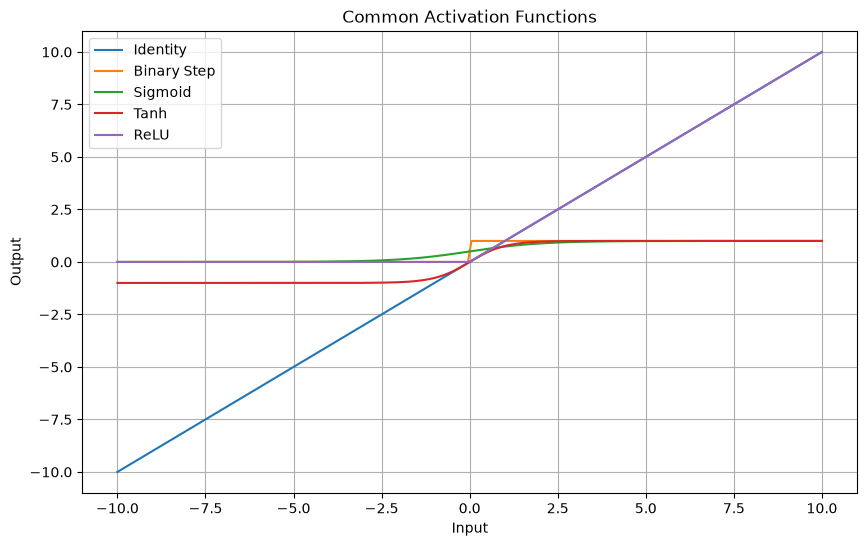

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 200)
identity = x
binary_step = np.where(x >= 0, 1, 0)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(10, 6))
plt.plot(x, identity, label='Identity')
plt.plot(x, binary_step, label='Binary Step')
plt.plot(x, sigmoid, label='Sigmoid')
plt.plot(x, tanh, label='Tanh')
plt.plot(x, relu, label='ReLU')
plt.title("Common Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.legend()
plt.show()


### 🧪 Interactive Experiment: TensorFlow Playground

Want to *experiment with neural networks* in real-time?

Click the link below to explore an interactive simulation using the **tanh activation function** and a **circular dataset**. Adjust parameters like learning rate, number of layers, and input features — and observe how the decision boundaries evolve.

👉 **[Launch the TensorFlow Playground Simulation](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.48465&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false)**

![Playground Preview](https://raw.githubusercontent.com/tensorflow/playground/master/images/playground.png)

🧠 Try changing the:
- Activation function (ReLU, tanh, sigmoid)
- Network shape (number of layers and neurons)
- Learning rate and batch size
- Input features (x, y, x², sin(x), etc.)

This is a powerful tool to build intuition about how neural networks **learn patterns**!



### 🗣️ Code Walkthrough Talking Points

- Each function maps input `x` to a transformed output — this controls how neurons activate.
- `Binary Step` is simple and fast but non-differentiable.
- `Sigmoid` and `Tanh` are smooth but suffer from vanishing gradients.
- `ReLU` is widely used due to efficiency and sparse activation.


## 🧠 Case Study: Are We Going to Canada's Wonderland?
We will now implement a simple artificial neural network using **PyTorch** to predict whether we’ll go to Canada's Wonderland based on three inputs:

- **X₁**: Weather — 1 if sunny, 0 if rainy
- **X₂**: Ticket queue — 1 if short, 0 if long
- **X₃**: Health — 1 if healthy, 0 if unwell

Each input has an associated **weight**, and the network uses a **bias** and a **sigmoid activation function** to generate a confidence value.

### 📊 Visual Summary: ANN Case Study – Are We Going to Canada's Wonderland?

Below is a visual walkthrough of the single-neuron prediction model:

| Slide 1 | Slide 2 |
|--------|--------|
| ![Slide 1](./images/ANN_1.png) | ![Slide 2](./images/ANN_2.png) |

| Slide 3 | Slide 4 |
|--------|--------|
| ![Slide 3](./images/ANN_3.png) | ![Slide 4](./images/ANN_4.png) |

| Slide 5 | Slide 6 |
|--------|--------|
| ![Slide 5](./images/ANN_5.png) | ![Slide 6](./images/ANN_6.png) |


### 🔢 Step 1: Prediction Function
We compute the neuron output $\hat{y}$ as:

$$
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{where} \quad z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b
$$

In our case:

- $x = [1, 0, 1]$
- $w = [5, 2, 4]$
- $b = -3$

In [2]:
import torch
import torch.nn as nn

# Inputs and weights
x = torch.tensor([1.0, 0.0, 1.0])
weights = torch.tensor([5.0, 2.0, 4.0])
bias = -3.0

# Linear combination
z = torch.dot(weights, x) + bias

# Sigmoid activation
sigmoid = torch.sigmoid(z)
print(f"z = {z.item():.2f}")
print(f"Predicted output (sigmoid) = {sigmoid.item():.4f}")

z = 6.00
Predicted output (sigmoid) = 0.9975


### 📈 Understanding the Output of Our Neuron

In the previous code cell, we computed the neuron's output using PyTorch:

```python
z = torch.dot(weights, x) + bias
sigmoid = torch.sigmoid(z)
```

#### 🔢 Here's how it breaks down:

Let’s plug in the numbers used in the slide (also shown in the code):

* Inputs: ( x = [1, 0, 1] )
* Weights: ( w = [5, 2, 4] )
* Bias: ( b = -3 )

The **linear combination** is computed as:

$$
\hat{y} = z = w_1x_1 + w_2x_2 + w_3x_3 + b = (1 \times 5) + (0 \times 2) + (1 \times 4) - 3 = 5 + 0 + 4 - 3 = 6
$$

Then, we pass this result through the **sigmoid activation function**:

$$
f(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^{-6}} \approx 0.9975
$$

This output is the **model’s confidence** (close to 1), which matches the slide’s annotation:

> “Therefore, we are going to Wonderland!”

🧠 **Interpretation**:

* Since $ \hat{y} = 6 $ and our threshold $ \tau = 3 $, and $ \hat{y} > \tau $, the neuron **fires**.
* The sigmoid output $ \approx 0.9975 $ tells us the model is **very confident** in its decision.

✅ Slide 2 in the table above, and the code are in **perfect agreement**.


### 💬 Talking Points
- We treat inputs like "sunny", "short queue", and "healthy" as binary features.
- The weighted sum (`z`) captures how favorable conditions are.
- Applying `sigmoid(z)` maps the decision to a probability.

### ❌ Step 2: Error Calculation
We compare the predicted value with the actual label:

$$
E = y - \hat{y}
$$

If the actual value is 1 (we should go), but our prediction is too low, we compute the error and update the weights.

In [3]:
y = torch.tensor(1.0)
error = y - sigmoid
print(f"Error = {error.item():.4f}")

Error = 0.0025


### 🧠 Talking Point: Why is the Error Different to that in the slides?

There’s an important distinction between **raw neuron output** $ \hat{y} $ and the **activated output** (confidence) $ f(z) $, which explains the discrepancy between:

* The error calculation in slide 4 in the table above is:
  $$
  E = y - \hat{y} = 1 - 6 = -5
  $$

* However, PyTorch code’s error calculation in the output above was:
  $$
  E = y - f(z) = 1 - 0.9975 = 0.0025
  $$

#### 🤔 What's happening?

* In **slides 4, 5 and 6**, the error is calculated using the raw linear output:
  $$
  \hat{y} = w_1x_1 + w_2x_2 + w_3x_3 + b = 6
  $$
  This is a **pre-activation** value, often used in gradient calculations during **backpropagation**.

* In the **code**, the error is computed using the **post-activation sigmoid output**:
  $$
  f(z) = \frac{1}{1 + e^{-6}} \approx 0.9975
  $$
  This represents the neuron's **confidence** in the prediction — suitable for binary classification.

#### 🧵 Summary:

* Use $ \hat{y} $ for training updates (e.g., computing loss and gradients).
* Use $ f(z) $ for interpreting prediction confidence.
* Both perspectives are valid — they serve **different roles** in learning and inference.

✅ This difference helps students understand **forward pass vs. backward pass** in training neural networks.


### 🔁 Step 3: Weight Update with Gradient Descent
Using a learning rate $\eta = 0.1$, we update each weight:

$$
w_j = w_j - \eta \cdot \frac{\partial L}{\partial w_j}
$$

We use PyTorch autograd to perform backpropagation.

In [4]:
x = x.clone().detach().requires_grad_(True)
weights = weights.clone().detach().requires_grad_(True)

z = torch.dot(weights, x) + bias
y_hat = torch.sigmoid(z)
loss = (y_hat - y) ** 2
loss.backward()

lr = 0.1
with torch.no_grad():
    weights -= lr * weights.grad
    print(f"Updated weights: {weights}")

Updated weights: tensor([5.0000, 2.0000, 4.0000], requires_grad=True)


> ### 🏠 Homework Challenge
>
> Study how to update the weights using **Gradient Descent**.
>
> 📌 **Question**: How is this update rule related to **Backpropagation** in multi-layer neural networks?
>

# 🧠 Single-Layer Perceptron: Visualizing Weights, Bias, and Activation

## Case #1 : C = A

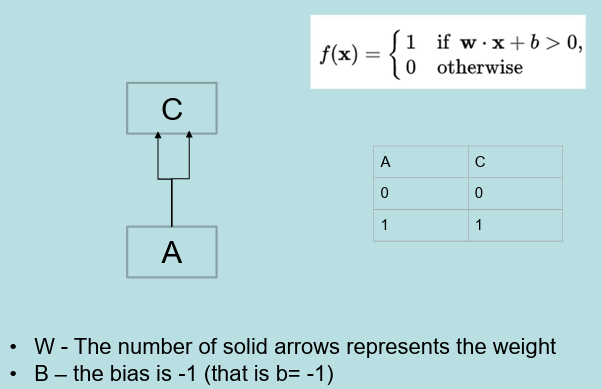



This perceptron has:

- One input node **A**
- One output node **C**
- Weight **w = 2** (represented by 2 arrows)
- Bias **b = -1**
- Activation function is a **step function**:
  
  $$
  f(x) = 
  \begin{cases} 
  1 & \text{if } w \cdot x + b > 0 \\
  0 & \text{otherwise}
  \end{cases}
  $$

Let's reproduce this in code using both **PyTorch** and **TensorFlow**.

---

## 🧪 PyTorch Implementation

Make sure to install these libraries in your virtual environment before you run the code:

```python
!pip install torch tensorflow notebook

```
```python
import torch

# Define weight and bias
w = torch.tensor(2.0)
b = torch.tensor(-1.0)

# Step activation function
def step(x):
    return 1 if x > 0 else 0

# Run for all inputs A = 0 or 1
for A in [0, 1]:
    x = torch.tensor(A, dtype=torch.float32)
    linear_output = w * x + b
    y = step(linear_output)
    print(f"Input A: {A} → Linear Output: {linear_output:.1f} → Output C: {y}")


In [5]:
import tensorflow as tf

# Define weight and bias
w = tf.constant(2.0)
b = tf.constant(-1.0)

# Step activation function
def step(x):
    return tf.where(x > 0, 1, 0)

# Run for all inputs A = 0 or 1
for A in [0, 1]:
    x = tf.constant(float(A))
    linear_output = w * x + b
    y = step(linear_output)
    print(f"Input A: {A} → Linear Output: {linear_output.numpy():.1f} → Output C: {y.numpy()}")


Input A: 0 → Linear Output: -1.0 → Output C: 0
Input A: 1 → Linear Output: 1.0 → Output C: 1


Here’s a side-by-side style comparison and integrated implementation of the Single-Layer Perceptron using both PyTorch and TensorFlow, formatted for a Jupyter Notebook. The goal is to clearly demonstrate how both frameworks approach the same logic:

In [6]:
# --- Imports ---
import torch
import tensorflow as tf

# --- Model Parameters (same for both) ---
weight = 2.0
bias = -1.0

# --- Step Activation Function (same logic) ---
def step(x):
    return 1 if x > 0 else 0

# --- Input values to test ---
inputs = [0, 1]

# --- PyTorch Implementation ---
print("🔵 PyTorch Perceptron Output")
for A in inputs:
    x_torch = torch.tensor(float(A))
    linear_output = weight * x_torch + bias
    output = step(linear_output.item())
    print(f"Input A: {A} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow Perceptron Output")
# --- TensorFlow Implementation ---
for A in inputs:
    x_tf = tf.constant(float(A))
    linear_output = weight * x_tf + bias
    output = step(linear_output.numpy())
    print(f"Input A: {A} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch Perceptron Output
Input A: 0 → Linear: -1.0 → Output C: 0
Input A: 1 → Linear: 1.0 → Output C: 1

🟢 TensorFlow Perceptron Output
Input A: 0 → Linear: -1.0 → Output C: 0
Input A: 1 → Linear: 1.0 → Output C: 1


### 🧠 AND Gate as a Perceptron: PyTorch vs TensorFlow

### Case #2 : C = A and B

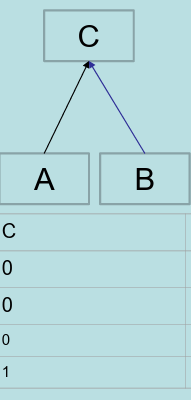

🧾 Model Description
Inputs: A, B

- Weight for A: 1
- Weight for B: 1
- Bias: -1.5

Activation: Step function (binary output)

In [7]:
import torch
import tensorflow as tf

# Shared configuration
weights = [1.0, 1.0]  # w_A = 1, w_B = 1
bias = -1.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch Perceptron Output")
for A, B in inputs:
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    linear_output = torch.dot(w, x) + bias
    output = step(linear_output.item())
    print(f"Input A={A}, B={B} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow Perceptron Output")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    linear_output = tf.reduce_sum(w * x) + bias
    output = step(linear_output.numpy())
    print(f"Input A={A}, B={B} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch Perceptron Output
Input A=0, B=0 → Linear: -1.5 → Output C: 0
Input A=1, B=0 → Linear: -0.5 → Output C: 0
Input A=0, B=1 → Linear: -0.5 → Output C: 0
Input A=1, B=1 → Linear: 0.5 → Output C: 1

🟢 TensorFlow Perceptron Output
Input A=0, B=0 → Linear: -1.5 → Output C: 0
Input A=1, B=0 → Linear: -0.5 → Output C: 0
Input A=0, B=1 → Linear: -0.5 → Output C: 0
Input A=1, B=1 → Linear: 0.5 → Output C: 1


### 🧠 OR Gate as a Perceptron: PyTorch vs TensorFlow

### Case #3 : C = A or B

🖼️ Diagram


💡 Code Walkthrough Talking Points

- Linear combination: The perceptron computes w₁·A + w₂·B + b. That’s the raw "score".
- Step activation: If the result > 0, output is 1; otherwise 0 — mimicking binary logic gates.
- Bias control: The bias -1.5 ensures that both A and B must be 1 to activate the output.

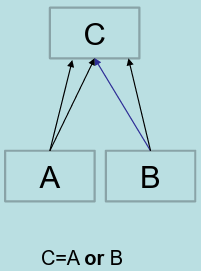

🧾 Model Description
Inputs: A, B

Weights:

- A → C: 1
- B → C: 2
- Bias: -0.5

Activation: Step function

In [8]:
import torch
import tensorflow as tf

# Model parameters
weights = [1.0, 2.0]  # A → 1, B → 2
bias = -0.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch OR Perceptron Output")
for A, B in inputs:
    # torch.tensor creates a new tensor (multi-dimensional array) from the given data.
    # Here, it converts the Python list [A, B] into a PyTorch tensor of type float32.
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    # torch.dot computes the dot product of two 1D tensors (vectors).
    # For example, torch.dot(w, x) = w[0]*x[0] + w[1]*x[1]
    linear_output = torch.dot(w, x) + bias
    output = step(linear_output.item())
    print(f"Input A={A}, B={B} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow OR Perceptron Output")
for A, B in inputs:
    # tf.constant creates a constant tensor from the given data.
    # Here, it converts the Python list [A, B] into a TensorFlow tensor of type float32.
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    linear_output = tf.reduce_sum(w * x) + bias
    output = step(linear_output.numpy())
    print(f"Input A={A}, B={B} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch OR Perceptron Output
Input A=0, B=0 → Linear: -0.5 → Output C: 0
Input A=1, B=0 → Linear: 0.5 → Output C: 1
Input A=0, B=1 → Linear: 1.5 → Output C: 1
Input A=1, B=1 → Linear: 2.5 → Output C: 1

🟢 TensorFlow OR Perceptron Output
Input A=0, B=0 → Linear: -0.5 → Output C: 0
Input A=1, B=0 → Linear: 0.5 → Output C: 1
Input A=0, B=1 → Linear: 1.5 → Output C: 1
Input A=1, B=1 → Linear: 2.5 → Output C: 1


### 💡 Code Walkthrough Talking Points
Weighting B more: Input B has a stronger influence on C (weight = 2), reflecting the blue arrow.

OR logic: With bias = -0.5, even a single active input (A or B) is enough to activate C.

Threshold control: The bias lowers the threshold so only one input needs to be active.


## 🧠 Inhibitory Logic in Perceptrons: Modeling C = A ∧ ¬B

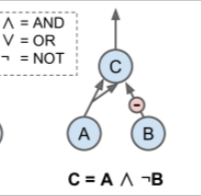

---

### 🔍 Description

- **Inputs**:
  - A (excitatory, weight = +1)
  - B (inhibitory, weight = -1)
- **Bias**: -0.5
- **Activation**: Step function

This neuron fires **only if** A is ON and B is OFF.

---


In [9]:
import torch
import tensorflow as tf

# Inputs: A, B
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]
weights = [1.0, -1.0]  # A=+1, B=-1
bias = -0.5

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch Implementation")
for A, B in inputs:
    print(f"Input A={A}, B={B}")
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    # torch.dot computes the dot product of two tensors.
    # Here, it calculates the weighted sum of inputs: z = w[0]*x + w[1]*x + bias
    z = torch.dot(w, x) + bias
    print(f"z (weighted sum) = {z.item():.1f}")
    y = step(z.item())
    print(f"A={A}, B={B} → z={z.item():.1f} → C={y}")

print("\n🟢 TensorFlow Implementation")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    z = tf.reduce_sum(w * x) + bias
    y = step(z.numpy())
    print(f"A={A}, B={B} → z={z.numpy():.1f} → C={y}")


🔵 PyTorch Implementation
Input A=0, B=0
z (weighted sum) = -0.5
A=0, B=0 → z=-0.5 → C=0
Input A=1, B=0
z (weighted sum) = 0.5
A=1, B=0 → z=0.5 → C=1
Input A=0, B=1
z (weighted sum) = -1.5
A=0, B=1 → z=-1.5 → C=0
Input A=1, B=1
z (weighted sum) = -0.5
A=1, B=1 → z=-0.5 → C=0

🟢 TensorFlow Implementation
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0



### 💬 Code Walkthrough Talking Points

- 🧲 **Inhibition as negative weight**: Neuron B has a weight of -1, which reduces the activation signal.
- 🚦 **Neuron must be off**: When B = 1, the negative weight prevents activation. This models logic gates with inhibition.
- 🧠 **Implements A AND NOT B**: This is a classic example of using simple perceptrons for logic circuits.


## 🧠 Challenge

### Use a Single Layer Perceptron to decide if you will go to the movies

Source: https://youtu.be/OFbnpY_k7js?si=aLIumFjjRtAMtxtm

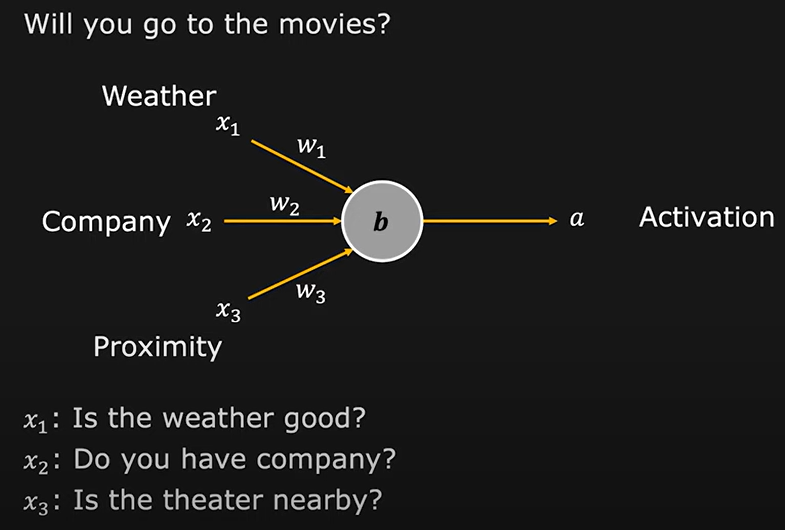

You can add and play with your own weights and biases.
Use the same activation function as in the examples above.
Add a talking point you can share with the class.

Here is a complete code cell implementing the single-layer perceptron to answer:

"Will you go to the movies?"
Based on: weather, company, and proximity

We'll use:

- Binary inputs x₁, x₂, x₃
- Weights: w₁ = 1.0 (weather), w₂ = 1.0 (company), w₃ = 1.0 (proximity)
- Bias b = -2.5 to require at least 3 "yes" answers to return a 1 (i.e., go to the movies)

In [10]:
from itertools import product

# Inputs: weather (x1), company (x2), proximity (x3)
weights = [1.0, 1.0, 1.0]   # w1, w2, w3
bias = -2.5                 # threshold: all three must be 1 for output = 1

def step(z):
    return 1 if z > 0 else 0

print("x1 x2 x3 | z      | Output")
print("----------------------------")
for x in product([0, 1], repeat=3):
    z = sum(w * xi for w, xi in zip(weights, x)) + bias
    output = step(z)
    print(f"{x[0]}  {x[1]}  {x[2]} | {z:>5.1f} |   {output}")


x1 x2 x3 | z      | Output
----------------------------
0  0  0 |  -2.5 |   0
0  0  1 |  -1.5 |   0
0  1  0 |  -1.5 |   0
0  1  1 |  -0.5 |   0
1  0  0 |  -1.5 |   0
1  0  1 |  -0.5 |   0
1  1  0 |  -0.5 |   0
1  1  1 |   0.5 |   1


🧠 Interpretation

- x₁: Is the weather good?
- x₂: Do you have company?
- x₃: Is the theater nearby?

Output 1 → You will go to the movies.

Output 0 → You won't go.

This simulates human-like logic where all conditions must be favorable.

### 🧠 How Does the Perceptron Behave as a Linear Classifier?

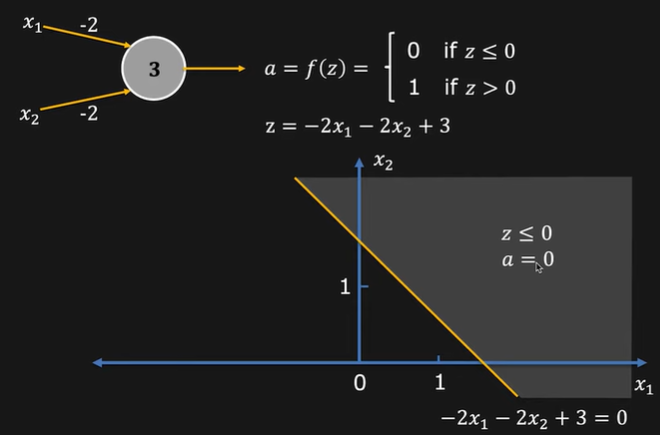

### 🧩 What's Happening in This Diagram?

- The **perceptron** computes:
  
  \[
  z = -2x_1 - 2x_2 + 3
  \]

- It then applies the **step activation**:
  
  $$
  a = 
  \begin{cases}
  1 & \text{if } z > 0 \\
  0 & \text{if } z \leq 0
  \end{cases}
  $$


### 📊 What Is the Yellow Line?

- It's the **decision boundary**, found by setting $z = 0$.
- That gives:

  $$
  -2x_1 - 2x_2 + 3 = 0 \quad \Rightarrow \quad x_2 = -x_1 + 1.5
  $$

- This line separates the input space into:

  - 🟡 **Above the line** → $z > 0$ → $a = 1$
  - ⚫ **Below or on the line** → $z \leq 0$ → $a = 0$


### 🧠 Why It Matters

This shows that a **single-layer perceptron classifies data using a straight line** (in 2D) — a **linear decision boundary**. If the inputs are linearly separable, the perceptron can perfectly classify them.


## 🧠 Challenge

Implement the Prostate Cancer prediction ANN in the Deep Learning Fundamentals class notes.

To do this:

1. Run and understand the provided Canada's Wonderland use case study and code provided with this workshop notebook.
2. Use them as a guide to implement new code and Markdown to explain it.
3. Add your Markdown, code and three talking points in the space below.

Keep the contents of the workshop and just add the new contents. 
Then copy the entire Jupyter notebook your own repository, and share the link to it for review.
Feel free to add the images folder so the notebook markdown shows the graphics it originally came with.


## Prostate Cancer Prediction ANN

In this section, I implement the prostate cancer example from the
Deep Learning Fundamentals slides using PyTorch. I follow the same
calculation steps as the Canada's Wonderland example.

The worked example uses one input: PSA, which stands for
prostate-specific antigen.

For the cancer prediction, the slides provide:

- PSA input: 2.0
- Weight: 2.747
- Bias: -5.754

The model multiplies the PSA value by its weight and adds the bias.
It then applies sigmoid to produce an estimated probability of cancer.

I use the following class labels:

- 1 = cancer
- 0 = healthy

The slides show cancer and healthy outputs. Since these probabilities
are complementary in this example, I calculate the cancer probability
and obtain the healthy probability as 1 minus the cancer probability.

After making the prediction, I calculate the error and loss using an
example target label, then perform one gradient descent update.
The target used for this update will be stated explicitly because the
prediction example does not provide a confirmed patient outcome.

The slides provide already-trained weights. I use these as the starting
values to demonstrate one additional learning step.

This is a classroom demonstration, not a diagnostic tool.

### Step 1: Set Up the Input, Weight, and Bias

I use the PSA input and cancer-output parameters from the class slides:

- Input: PSA = 2.0
- Weight: 2.747
- Bias: -5.754

The weight controls how strongly PSA affects the raw score.
The bias shifts that score before sigmoid is applied.

I set `requires_grad=True` for the weight and bias so PyTorch can
calculate their gradients.

For the learning demonstration, I assume a target of 0, meaning healthy.
This is an assumed training label, not a confirmed outcome supplied
by the prediction slide.

I use a learning rate of 0.1 to perform one parameter update.

In [11]:
import torch

# PSA input from the class slides
pc_x = torch.tensor([2.0], dtype=torch.float32)

# Cancer-output weight and bias from the slides
pc_weights = torch.tensor(
    [2.747],
    dtype=torch.float32,
    requires_grad=True
)

pc_bias = torch.tensor(
    -5.754,
    dtype=torch.float32,
    requires_grad=True
)

# Assumed training label for demonstrating one update:
# 0 = healthy, 1 = cancer
pc_target = torch.tensor(0.0, dtype=torch.float32)

pc_learning_rate = 0.1

print(f"PSA input: {pc_x.item():.3f}")
print(f"Initial weight: {pc_weights.item():.3f}")
print(f"Initial bias: {pc_bias.item():.3f}")
print(f"Assumed target: {int(pc_target.item())} (healthy)")
print(f"Learning rate: {pc_learning_rate}")

PSA input: 2.000
Initial weight: 2.747
Initial bias: -5.754
Assumed target: 0 (healthy)
Learning rate: 0.1


### Step 2: Calculate the Prediction

First, I multiply the PSA input by its weight and add the bias:

$$
z = wx + b
$$

Using the values from the slides:

$$
z = (2.747 \times 2.0) - 5.754 = -0.260
$$

Next, I apply sigmoid to calculate the estimated cancer probability:

$$
P(\text{cancer}) = \frac{1}{1 + e^{-z}} \approx 0.4354
$$

The healthy probability is:

$$
P(\text{healthy}) = 1 - P(\text{cancer}) \approx 0.5646
$$

Using a threshold of 0.5, the model predicts class 0 (healthy),
because the cancer probability is below 0.5.

The slide reports approximately 0.438 for cancer. However, its displayed
weight, input, and bias give z = -0.260 rather than -0.251.
My code uses the displayed parameters consistently.

In [12]:
# Calculate the raw score
pc_z = torch.dot(pc_weights, pc_x) + pc_bias

# Calculate cancer and healthy probabilities
pc_prediction = torch.sigmoid(pc_z)
pc_healthy_probability = 1 - pc_prediction

# Apply a threshold to the cancer probability
pc_predicted_class = int(pc_prediction.item() >= 0.5)
pc_class_name = "Cancer" if pc_predicted_class == 1 else "Healthy"

print(f"Raw score (z): {pc_z.item():.4f}")
print(f"Cancer probability: {pc_prediction.item():.4f}")
print(f"Healthy probability: {pc_healthy_probability.item():.4f}")
print(f"Predicted class: {pc_predicted_class} ({pc_class_name})")
print(f"Assumed training target: {int(pc_target.item())}")

Raw score (z): -0.2600
Cancer probability: 0.4354
Healthy probability: 0.5646
Predicted class: 0 (Healthy)
Assumed training target: 0


### Step 3: Calculate the Error and Loss

For this learning demonstration, I assume the patient is healthy,
so the target is 0.

The error is the target minus the predicted cancer probability:

$$
E = y - \hat{y}
$$

$$
E = 0 - 0.4354 \approx -0.4354
$$

The negative error means the predicted cancer probability is above
the assumed target.

Following the Wonderland code, I use squared error as the loss:

$$
L = (\hat{y} - y)^2
$$

$$
L = (0.4354 - 0)^2 \approx 0.1895
$$

Although the predicted class is already healthy, the loss is greater
than zero because the predicted cancer probability is not exactly 0.
The update will try to reduce this loss.

In [13]:
# Compare the cancer probability with the assumed target
pc_error = pc_target - pc_prediction

# Squared-error loss, following the Wonderland example
pc_loss = (pc_prediction - pc_target) ** 2

# Save values for comparison after the update
pc_prediction_before = pc_prediction.item()
pc_loss_before = pc_loss.item()

print(f"Assumed target: {pc_target.item():.0f}")
print(f"Predicted cancer probability: {pc_prediction_before:.4f}")
print(f"Error: {pc_error.item():.4f}")
print(f"Loss before update: {pc_loss_before:.4f}")

Assumed target: 0
Predicted cancer probability: 0.4354
Error: -0.4354
Loss before update: 0.1895


### Step 4: Perform One Gradient Descent Update

I use backpropagation to calculate how the loss changes with respect
to the PSA weight and bias.

In PyTorch, `pc_loss.backward()` calculates these gradients.
It does not change the parameters itself.

I then apply gradient descent:

$$
w_{\text{new}} = w_{\text{old}} - \eta \frac{\partial L}{\partial w}
$$

$$
b_{\text{new}} = b_{\text{old}} - \eta \frac{\partial L}{\partial b}
$$

The learning rate is 0.1.

For this example, both gradients are positive, so the update decreases
the weight and bias. With the positive PSA input, this lowers the raw
score and cancer probability, moving the prediction toward the assumed
healthy target of 0.

I use `torch.no_grad()` while changing the parameters so PyTorch does
not track the update operations as part of the gradient calculation.

In [14]:
# Clear gradients from any previous execution
pc_weights.grad = None
pc_bias.grad = None

# Calculate the prediction and loss using the current parameters
pc_z = torch.dot(pc_weights, pc_x) + pc_bias
pc_prediction = torch.sigmoid(pc_z)
pc_loss = (pc_prediction - pc_target) ** 2

# Save the values before this update
pc_prediction_before = pc_prediction.item()
pc_loss_before = pc_loss.item()
pc_weight_before = pc_weights.item()
pc_bias_before = pc_bias.item()

# Backpropagation: calculate gradients
pc_loss.backward()

print(f"Weight gradient: {pc_weights.grad.item():.6f}")
print(f"Bias gradient: {pc_bias.grad.item():.6f}")

# Gradient descent: perform one update
with torch.no_grad():
    pc_weights -= pc_learning_rate * pc_weights.grad
    pc_bias -= pc_learning_rate * pc_bias.grad

print(f"\nWeight: {pc_weight_before:.6f} → {pc_weights.item():.6f}")
print(f"Bias: {pc_bias_before:.6f} → {pc_bias.item():.6f}")

Weight gradient: 0.428088
Bias gradient: 0.214044

Weight: 2.747000 → 2.704191
Bias: -5.754000 → -5.775404


### Step 5: Check the Result After the Update

I calculate the cancer probability and loss again using the updated
weight and bias.

Since the assumed target is 0 (healthy), a lower cancer probability
means the prediction is closer to this target.

I compare the loss before and after the update to check whether this
single learning step improved the prediction for the example.

The predicted class may stay healthy even though the probability
and loss change. Learning can improve the prediction without changing
its class label.

This comparison only shows improvement on the example used for
the update. It does not measure performance on other patients.

In [15]:
# Evaluate the updated model without tracking gradients
with torch.no_grad():
    pc_new_z = torch.dot(pc_weights, pc_x) + pc_bias
    pc_new_prediction = torch.sigmoid(pc_new_z)
    pc_new_loss = (pc_new_prediction - pc_target) ** 2

pc_new_class = int(pc_new_prediction.item() >= 0.5)
pc_new_class_name = "Cancer" if pc_new_class == 1 else "Healthy"

print(f"Cancer probability before: {pc_prediction_before:.4f}")
print(f"Cancer probability after:  {pc_new_prediction.item():.4f}")

print(f"\nLoss before update: {pc_loss_before:.4f}")
print(f"Loss after update:  {pc_new_loss.item():.4f}")

print(f"\nPredicted class after update: {pc_new_class_name}")
print(f"Did the loss decrease? {pc_new_loss.item() < pc_loss_before}")

Cancer probability before: 0.4354
Cancer probability after:  0.4093

Loss before update: 0.1895
Loss after update:  0.1675

Predicted class after update: Healthy
Did the loss decrease? True


### Understanding My Results

The model uses PSA = 2.0, a starting weight of 2.747, and a
starting bias of -5.754 from the class slides.

Before the update, the cancer probability was approximately 0.4354.
Since this is below 0.5, the predicted class was healthy.

For the learning demonstration, I assumed a healthy target of 0.
This is an example training label, not a confirmed patient outcome
supplied by the prediction slide.

After one gradient descent update, the cancer probability decreased
to approximately 0.4093. The loss decreased from approximately
0.1895 to 0.1675.

Both the weight and bias decreased because their gradients were
positive. These changes lowered the raw score and cancer probability,
moving the prediction closer to the assumed target.

The predicted class remained healthy. This shows that learning can
reduce the loss without changing the predicted class.

This demonstrates improvement on one example, not accuracy on
other patients.

### Three Talking Points

1. **How prediction works:** The neuron multiplies the PSA input by
   its weight and adds the bias. Sigmoid converts this raw score into
   an estimated cancer probability. In this example, the healthy
   probability is 1 minus the cancer probability.

2. **Why loss is needed:** I compare the prediction with an assumed
   healthy target of 0. Squared-error loss measures the difference.
   Even when the predicted class is correct, the loss can still
   decrease as the probability moves closer to the target.

3. **How learning works:** `pc_loss.backward()` calculates gradients.
   Gradient descent uses those gradients to update the weight and
   bias. After one update, the cancer probability decreased from
   0.4354 to 0.4093, and the loss decreased from 0.1895 to 0.1675.

# Homework: Gradient Descent and Backpropagation

## Question

How is gradient descent related to backpropagation?

In this homework, I ran the `MinimalSingleSayerPerceptronTrainingLoop.py` Python script, which trains a single-layer perceptron to learn the OR logical function.

The objective is to understand how backpropagation calculates gradients and how gradient descent uses those gradients to update the weights and bias during training.

I will also use the Python debugger to observe how the weights and bias change over the 20 training epochs.

## 1. Relationship Between Gradient Descent and Backpropagation

Gradient descent and backpropagation work together to train a neural network.

**Backpropagation** calculates the gradients of the loss function with respect to the weights and bias. It uses the chain rule to determine how much each parameter contributes to the prediction error.

**Gradient descent** uses these calculated gradients to update the weights and bias to reduce the loss.

In simple terms:

- Backpropagation calculates the gradients and determines how the weights and bias should change.
- Gradient descent uses these gradients to update the model parameters.
- The learning rate controls the size of each update.

In the Python training script, `loss.backward()` performs backpropagation and calculates the gradients.

The following statements perform the gradient descent updates:

```python
weights -= lr * weights.grad
bias -= lr * bias.grad
```


## 2. Understanding the OR Function

The training script uses the OR logical function.

The OR function produces an output of 1 when at least one input is 1. It produces 0 only when both inputs are 0.

The training dataset contains four input combinations:

| Input A | Input B | Expected Output |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 1 |

The perceptron learns this relationship by adjusting its weights and bias during training.

The training process uses 20 epochs. One epoch represents one complete pass through the four training examples.

In [16]:
# Execute the provided OR function training script
import runpy
result = runpy.run_path("MinimalSingleSayerPerceptronTrainingLoop.py")

Weights after epoch 1: [1.5409960746765137, -0.293428897857666]
Bias after epoch 1: -2.1806
Weights after epoch 1: [1.5409960746765137, -0.28021061420440674]
Bias after epoch 1: -2.1674
Weights after epoch 1: [1.5705814361572266, -0.28021061420440674]
Bias after epoch 1: -2.1378
Weights after epoch 1: [1.5999809503555298, -0.2508111298084259]
Bias after epoch 1: -2.1084
Epoch 1, Loss = 1.7757
Weights after epoch 2: [1.5999809503555298, -0.2508111298084259]
Bias after epoch 2: -2.1105
Weights after epoch 2: [1.5999809503555298, -0.23641951382160187]
Bias after epoch 2: -2.0961
Weights after epoch 2: [1.6292219161987305, -0.23641951382160187]
Bias after epoch 2: -2.0669
Weights after epoch 2: [1.6588479280471802, -0.20679347217082977]
Bias after epoch 2: -2.0373
Epoch 2, Loss = 1.6719
Weights after epoch 3: [1.6588479280471802, -0.20679347217082977]
Bias after epoch 3: -2.0396
Weights after epoch 3: [1.6588479280471802, -0.19114693999290466]
Bias after epoch 3: -2.0240
Weights after epoc

## 3. Training Results: Changes in Weights and Bias

After running the OR function training script, I observed that the weights and bias changed throughout the 20 training epochs.

The model processes four training examples in each epoch and updates its parameters after each example. Therefore, there are four parameter updates per epoch.

### Observations

**Weight 1:** Weight 1 increased from 1.5410 to 2.2480. This shows that the model gradually adjusted the influence of the first input.

**Weight 2:** Weight 2 increased from -0.2934 to 0.5090. It started with a negative value and became positive during epoch 7.

**Bias:** The bias increased from -2.1788 to -1.1028. Although it remained negative, it gradually became less negative.

**Loss:** The loss decreased from 1.7757 in epoch 1 to 0.5839 in epoch 20.

### Interpretation

The results demonstrate how gradient descent adjusts the weights and bias using the gradients calculated through backpropagation.

The weights and bias are updated after each training example. These repeated updates help the model reduce its prediction error and learn the OR function.

In [17]:
import pandas as pd

# Create training history using the final values from each epoch
training_history = pd.DataFrame({
    "Epoch": list(range(1, 21)),
    "Weight 1": [
        1.6000, 1.6588, 1.7167, 1.7725, 1.8255,
        1.8752, 1.9211, 1.9633, 2.0017, 2.0365,
        2.0680, 2.0965, 2.1223, 2.1456, 2.1668,
        2.1861, 2.2036, 2.2197, 2.2345, 2.2480
    ],
    "Weight 2": [
        -0.2508, -0.2068, -0.1619, -0.1167, -0.0716,
        -0.0271, 0.0166, 0.0593, 0.1010, 0.1417,
        0.1815, 0.2205, 0.2587, 0.2962, 0.3331,
        0.3694, 0.4052, 0.4403, 0.4749, 0.5090
    ],
    "Bias": [
        -2.1084, -2.0373, -1.9662, -1.8960, -1.8277,
        -1.7616, -1.6984, -1.6380, -1.5806, -1.5261,
        -1.4742, -1.4249, -1.3779, -1.3331, -1.2904,
        -1.2495, -1.2103, -1.1729, -1.1371, -1.1028
    ],
    "Loss": [
        1.7757, 1.6719, 1.5668, 1.4631, 1.3634,
        1.2699, 1.1838, 1.1056, 1.0352, 0.9720,
        0.9153, 0.8641, 0.8178, 0.7756, 0.7371,
        0.7016, 0.6688, 0.6385, 0.6102, 0.5839
    ]
})

training_history

,Epoch,Weight 1,Weight 2,Bias,Loss
0,1,1.6000,-0.2508,-2.1084,1.7757
1,2,1.6588,-0.2068,-2.0373,1.6719
2,3,1.7167,-0.1619,-1.9662,1.5668
3,4,1.7725,-0.1167,-1.8960,1.4631
4,5,1.8255,-0.0716,-1.8277,1.3634
5,6,1.8752,-0.0271,-1.7616,1.2699
6,7,1.9211,0.0166,-1.6984,1.1838
7,8,1.9633,0.0593,-1.6380,1.1056
8,9,2.0017,0.1010,-1.5806,1.0352
9,10,2.0365,0.1417,-1.5261,0.9720


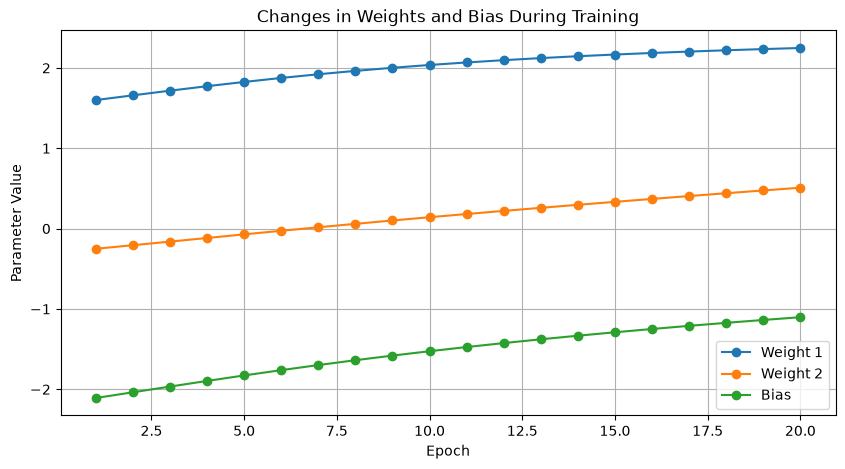

In [18]:
import matplotlib.pyplot as plt

# Plot weights and bias over the epochs
plt.figure(figsize=(10, 5))

plt.plot(training_history["Epoch"],
         training_history["Weight 1"],
         marker="o",
         label="Weight 1")

plt.plot(training_history["Epoch"],
         training_history["Weight 2"],
         marker="o",
         label="Weight 2")

plt.plot(training_history["Epoch"],
         training_history["Bias"],
         marker="o",
         label="Bias")

plt.xlabel("Epoch")
plt.ylabel("Parameter Value")
plt.title("Changes in Weights and Bias During Training")
plt.legend()
plt.grid(True)
plt.show()

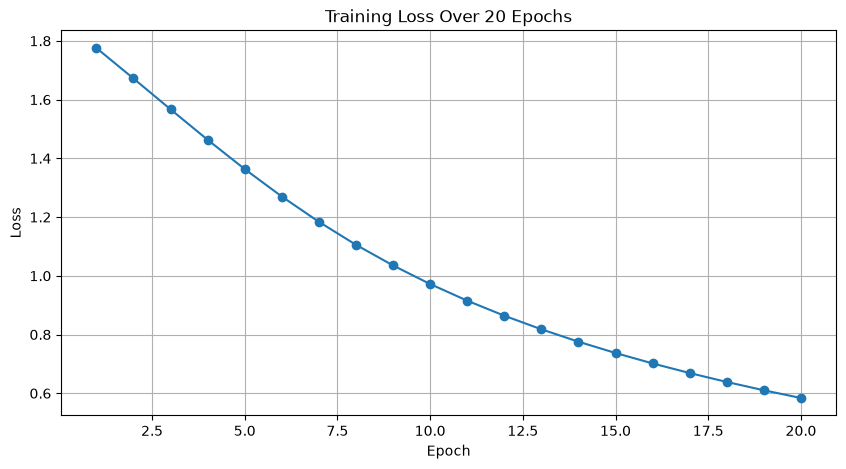

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(training_history["Epoch"],
         training_history["Loss"],
         marker="o")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Over 20 Epochs")
plt.grid(True)
plt.show()

### Analysis of Training Results

The graphs show how the weights, bias, and loss changed during the 20 training epochs.

Weight 1 increased from approximately 1.60 to 2.25, while Weight 2 increased from approximately -0.25 to 0.51. The bias also increased from approximately -2.11 to -1.10. These changes occurred because gradient descent updated the model parameters using the gradients calculated during backpropagation.

The loss decreased from approximately 1.78 in Epoch 1 to 0.58 in Epoch 20. This indicates that the model gradually improved its predictions during training.

Overall, the graphs demonstrate that backpropagation calculates the gradients and gradient descent uses those gradients to update the weights and bias. The decreasing loss shows that the training process is moving in the right direction.

### Debugging Observations

I used the VS Code debugger to step through the perceptron training script.

During debugging, I observed the following:

1. **Initial parameters:** The model starts with randomly initialized weights and bias.
2. **Forward pass:** The model calculates the weighted sum using the input values, weights, and bias.
3. **Prediction:** The sigmoid activation function converts the weighted sum into a prediction between 0 and 1.
4. **Loss calculation:** The loss function measures the difference between the predicted output and the actual output.
5. **Backpropagation:** The `loss.backward()` statement calculates gradients for the weights and bias.
6. **Parameter updates:** Gradient descent uses these gradients to update the weights and bias.
7. **Repeated training:** These steps repeat for each training example across all 20 epochs.

The debugger helped me understand how the model calculates predictions, determines errors, calculates gradients, and updates its parameters during training.

### Conclusion

This homework helped me understand the relationship between gradient descent and backpropagation. Backpropagation calculates the gradients that indicate how the weights and bias should change. Gradient descent uses these gradients to update the parameters and reduce the loss.

The training results showed that the loss decreased from approximately 1.78 to 0.58 over 20 epochs. This demonstrates that the perceptron gradually improved its predictions while learning the OR function.